# Compare countries in terms of temperatures

Vergelijk de gemiddelde temperatuur van verschillende landen. <br>
Identificeer de landen met de hoogste en laagste temperaturen. <br>
Maak duidelijke visualisaties om deze verschillen duidelijk te maken. <br>

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

In [28]:
engine = create_engine(
    "mysql+pymysql://root@localhost:3306/climate_watch"
)

df_country = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCountry", con=engine, parse_dates=["dt"])
df_country_sorted = df_country.sort_values(["Country", "dt"])

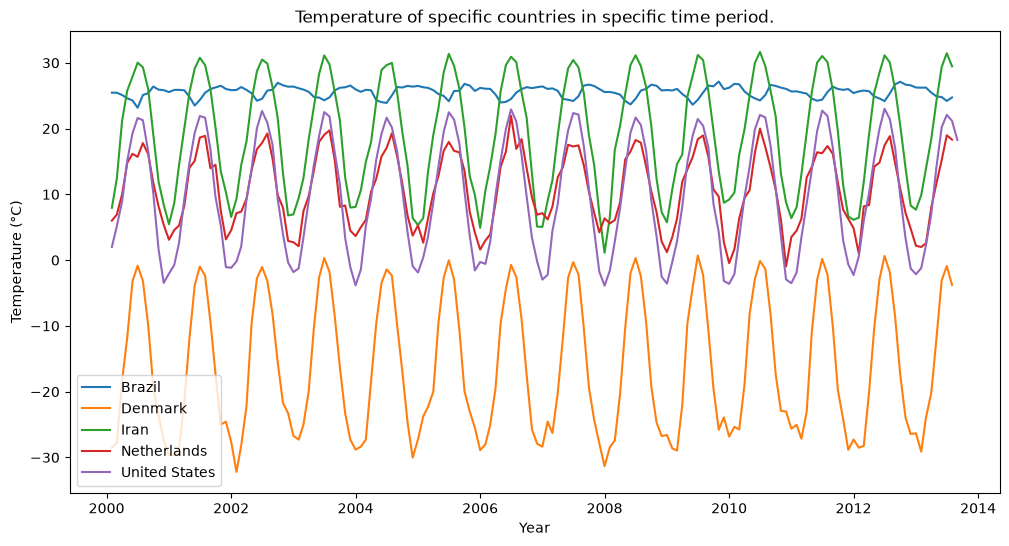

In [118]:
# Show temperature of specific countries in a date range

start_date = "2000-01-01"
end_date = "2015-01-01"

country_list = [
    "Netherlands",
    "Denmark",
    "United States",
    "Brazil",
    "Iran",
]

df_country_filter_date = df_country_sorted[
    (df_country_sorted["dt"] > start_date)
    & (df_country_sorted["dt"] < end_date)
]
df_country_filter_name = df_country_filter_date[df_country_filter_date["Country"].isin(country_list)]

df_country_pivot = df_country_filter_name.pivot(
    index="dt",
    columns="Country",
    values="AverageTemperature"
)

fig = plt.figure(figsize=(12,6))
plt.plot(df_country_pivot.index, df_country_pivot)
plt.legend(df_country_pivot.columns)
plt.title("Temperature of specific countries in specific time period.")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.show()

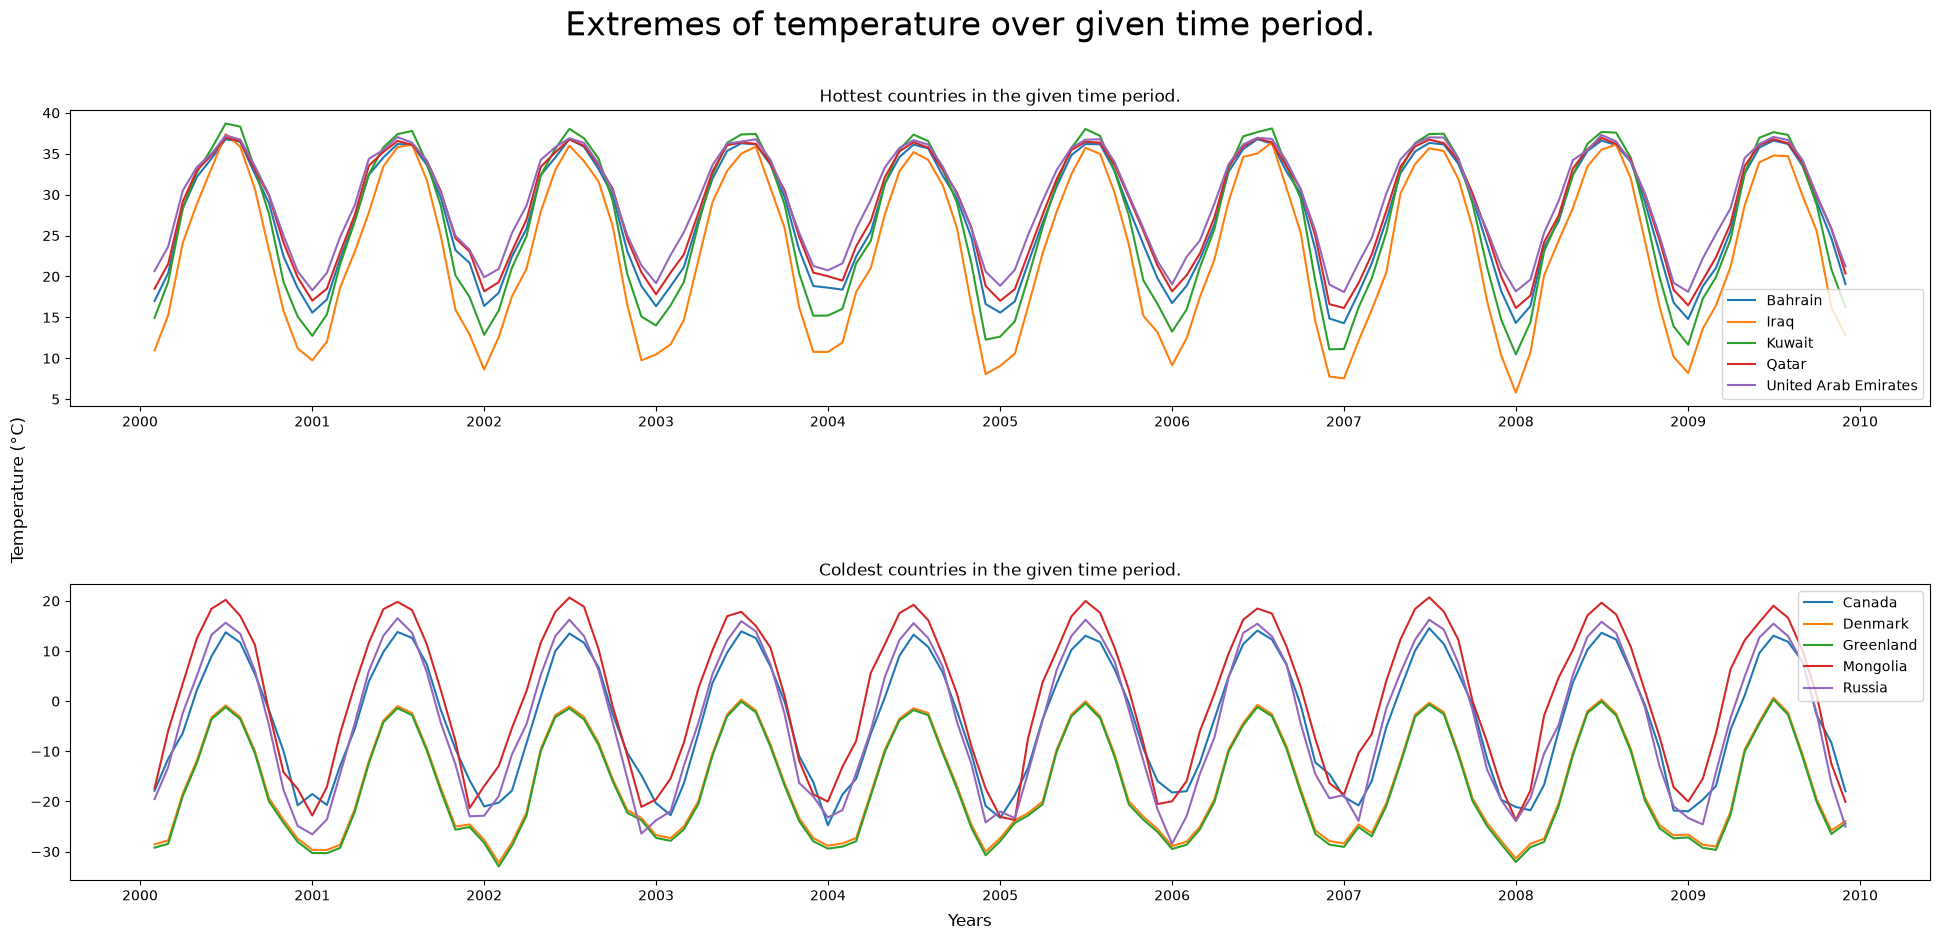

In [134]:
# Show the hottest and coldest countries for a given time period
start_date = "2000-01-01"
end_date = "2010-01-01"

df_country_filter_date = df_country_sorted[
    (df_country_sorted["dt"] > start_date)
    & (df_country_sorted["dt"] < end_date)
]

# Hottest 5 countries
df_highest_temp = df_country_filter_date.sort_values(["AverageTemperature"], ascending=False)
hottest_countries = df_highest_temp["Country"].unique().tolist()[:5]

df_country_filter_name_hot = df_country_filter_date[df_country_filter_date["Country"].isin(hottest_countries)]

df_country_pivot_hot = df_country_filter_name_hot.pivot(
    index="dt",
    columns="Country",
    values="AverageTemperature"
)

# Coldest 5 countries
df_lowest_temp = df_country_filter_date.sort_values(["AverageTemperature"], ascending=True)
hottest_countries = df_lowest_temp["Country"].unique().tolist()[:5]

df_country_filter_name_cold = df_country_filter_date[df_country_filter_date["Country"].isin(hottest_countries)]

df_country_pivot_cold = df_country_filter_name_cold.pivot(
    index="dt",
    columns="Country",
    values="AverageTemperature"
)

# Show results
fig, ax = plt.subplots(2,1,figsize=(24,10))
fig.subplots_adjust(hspace=0.6)
fig.suptitle("Extremes of temperature over given time period.", fontsize=24)
fig.supylabel("Temperature (°C)", x=0.1)
fig.supxlabel("Years", y=0.06)

ax[0].plot(df_country_pivot_hot.index, df_country_pivot_hot)
ax[0].legend(df_country_pivot_hot.columns)
ax[0].title.set_text("Hottest countries in the given time period.")

ax[1].plot(df_country_pivot_cold.index, df_country_pivot_cold)
ax[1].legend(df_country_pivot_cold.columns)
ax[1].title.set_text("Coldest countries in the given time period.")

plt.show()

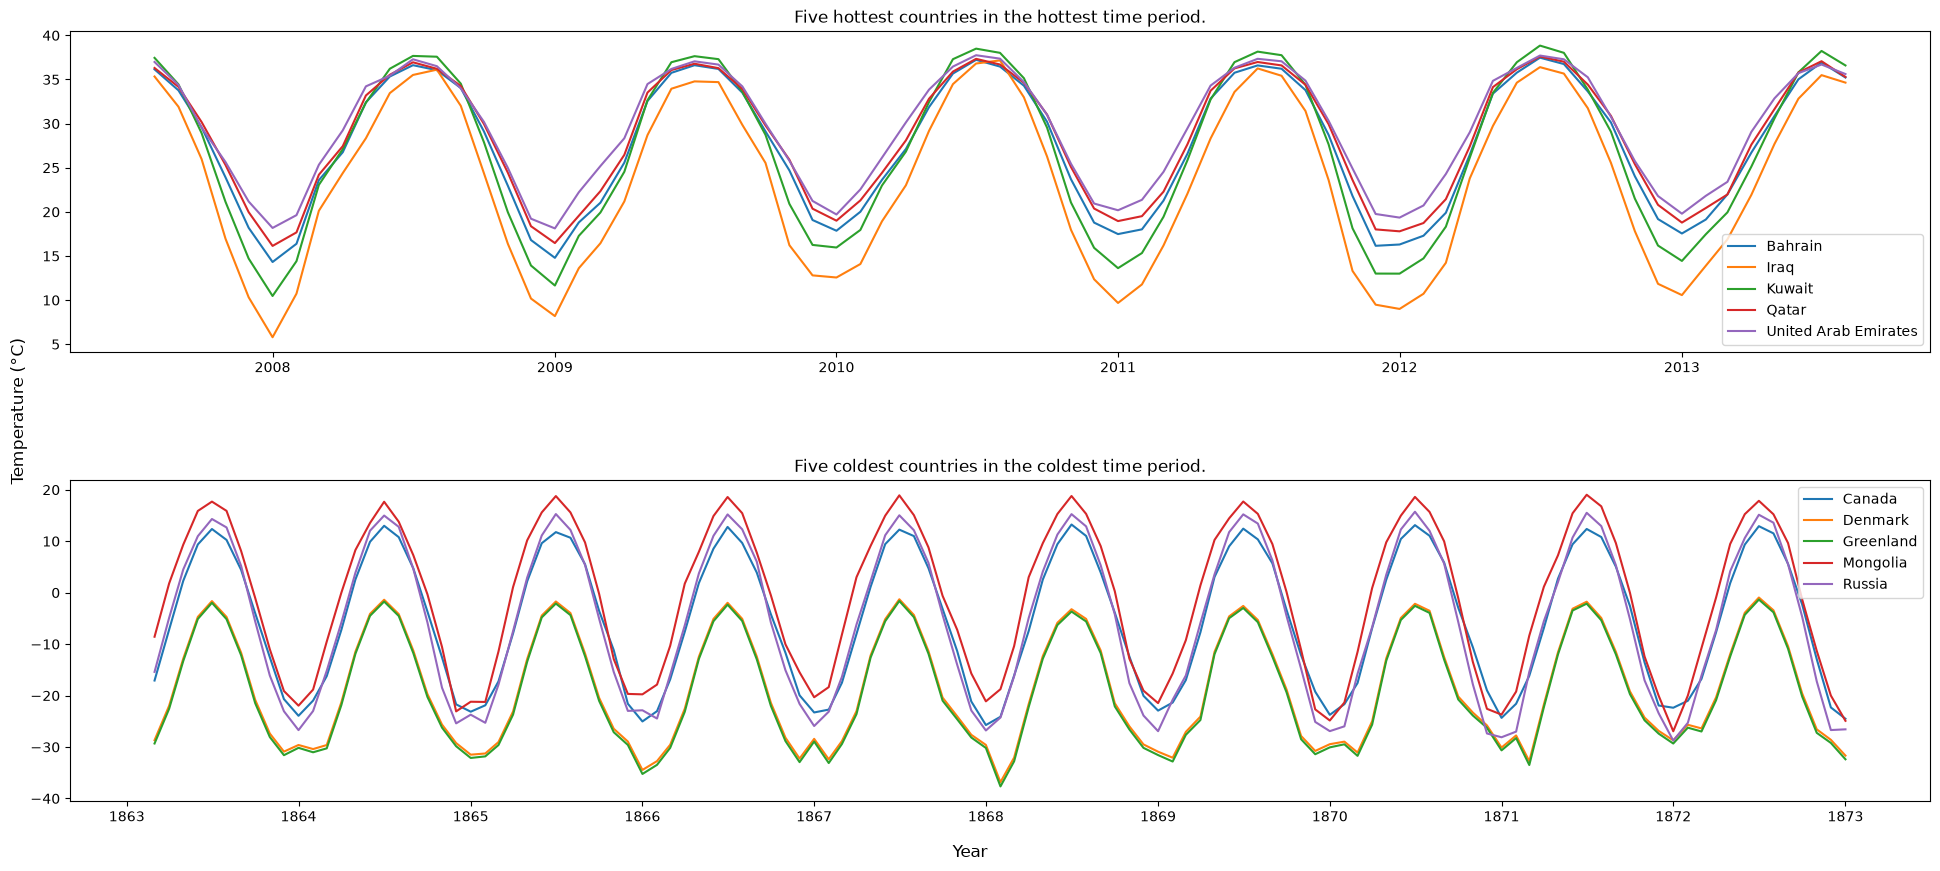

In [139]:
# Filter to the time period of the hottest and coldest temperature recorded.
# Then show the hottest and coldest countries of that time period.

# Find hottest time period
hottest_temp = df_country["AverageTemperature"].max()
hottest_date = df_country[df_country["AverageTemperature"] == hottest_temp].iloc[0]["dt"]
start_date = hottest_date - pd.DateOffset(years=5)
end_date = hottest_date + pd.DateOffset(years=5)

df_country_filter_date_hot = df_country_sorted[
    (df_country_sorted["dt"] > start_date)
    & (df_country_sorted["dt"] < end_date)
]

# Find 5 hottest countries
df_highest_temp = df_country_filter_date_hot.sort_values(["AverageTemperature"], ascending=False)
hottest_countries = df_highest_temp["Country"].unique().tolist()[:5]

df_country_filter_name_hot = df_country_filter_date_hot[df_country_filter_date_hot["Country"].isin(hottest_countries)]

df_country_pivot_hot = df_country_filter_name_hot.pivot(
    index="dt",
    columns="Country",
    values="AverageTemperature"
)


# Find coldest time period
coldest_temp = df_country["AverageTemperature"].min()
coldest_date = df_country[df_country["AverageTemperature"] == coldest_temp].iloc[0]["dt"]
start_date = coldest_date - pd.DateOffset(years=5)
end_date = coldest_date + pd.DateOffset(years=5)

df_country_filter_date_cold = df_country_sorted[
    (df_country_sorted["dt"] > start_date)
    & (df_country_sorted["dt"] < end_date)
]

# Find 5 coldest countries
df_highest_temp = df_country_filter_date_cold.sort_values(["AverageTemperature"], ascending=True)
coldest_countries = df_highest_temp["Country"].unique().tolist()[:5]

df_country_filter_name_cold = df_country_filter_date_cold[df_country_filter_date_cold["Country"].isin(coldest_countries)]

df_country_pivot_cold = df_country_filter_name_cold.pivot(
    index="dt",
    columns="Country",
    values="AverageTemperature"
)


# Show results
fig, ax = plt.subplots(2,1,figsize=(24,10))
fig.subplots_adjust(hspace=0.4)
fig.supxlabel("Year", y=0.05)
fig.supylabel("Temperature (°C)", x=0.1)

ax[0].plot(df_country_pivot_hot.index, df_country_pivot_hot)
ax[0].legend(df_country_pivot_hot.columns)
ax[0].title.set_text("Five hottest countries in the hottest time period.")

ax[1].plot(df_country_pivot_cold.index, df_country_pivot_cold)
ax[1].legend(df_country_pivot_cold.columns)
ax[1].title.set_text("Five coldest countries in the coldest time period.")


plt.show()